# Projection bake-off, full 2025 season

`projection_bakeoff.ipynb` held out only weeks 4 and 5 of 2026 (the saved fixture). This notebook runs the **same comparison over a whole
finished season**: 2025, test weeks 4-17, rolling origin (each test week is predicted by models trained on earlier weeks only). Same four
candidates, same features, same hyperparameters, same floor / ceiling check:

1. **projection**: Sleeper's weekly projection, scored with the league's scoring.
2. **residual_gbm**: projection + 0.3 × a gradient-boosted correction of the projection's residual.
3. **shrink_to_avg**: projection shrunk toward the player's season average, weight `gp / (gp + 10)`.
4. **gbm**: gradient boosting on form, snap share and matchup grade.

Rule, as before: if the plain projection does not win, say so; nothing here is tuned to make it win.

**Caveat: these MAEs flatter real-time projections.** Sleeper rewrites a past week's projection after the games: the projection endpoint
returns, for a finished week, a line that already knows who sat out. The check further down confirms it for 2025 (no player projected above
0.5 points ever lacks a game). So every MAE here is the error of an *after-the-fact* projection, smaller than what the app showed before
kickoff. The ML candidates are built on the same rewritten projection, so the *ranking* is a fair comparison; the *level* is optimistic.
`projection_bakeoff_refresh.ipynb` measures how big the flattery is on 2026 week 6.

## Data: Sleeper's public API, cached on disk

Same `get()` as `odds_calibration.ipynb`: every response is kept gzipped under `notebooks/.cache/sleeper/` (git-ignored) and reused, so
after the first run (or after `odds_calibration.ipynb` has run) nothing is downloaded. 2025 is finished, so cached responses never go stale.

Scoring comes from the owner's 2025 league, *goon squad* (full PPR, 4-point passing TDs, no catch bonuses).

In [1]:
import gzip, hashlib, json, time, urllib.request, urllib.error
from concurrent.futures import ThreadPoolExecutor
from functools import lru_cache
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor

pd.set_option('display.width', 140)
CACHE = Path('.cache') / 'sleeper'
CACHE.mkdir(parents=True, exist_ok=True)
BASE = 'https://api.sleeper.app'
OUT = Path('..') / 'docs' / 'validation'

def get(path):
    # GET a Sleeper path (e.g. '/v1/league/123'), cached forever on disk. Returns None on a 404.
    f = CACHE / (hashlib.sha1(path.encode()).hexdigest()[:20] + '.json.gz')
    if f.exists():
        with gzip.open(f, 'rt') as fh: return json.load(fh)
    for attempt in range(5):
        try:
            with urllib.request.urlopen(BASE + path, timeout=30) as r:
                data = json.load(r)
            break
        except urllib.error.HTTPError as e:
            if e.code == 404: data = None; break
            time.sleep(1 + 2 * attempt)
        except Exception:
            time.sleep(1 + 2 * attempt)
    else:
        raise RuntimeError('failed: ' + path)
    with gzip.open(f, 'wt') as fh: json.dump(data, fh)
    return data

def get_many(paths, workers=8):
    with ThreadPoolExecutor(workers) as ex:
        return list(ex.map(get, paths))

SEASON = '2025'
OWNER_LEAGUE_2025 = '1270085638657413120'           # goon squad
POS = ['QB', 'RB', 'WR', 'TE', 'K', 'DEF']
POSI = {p: i for i, p in enumerate(POS)}
WEEKS = list(range(1, 19))
q = '&'.join(f'position[]={p}' for p in POS)
league = get(f'/v1/league/{OWNER_LEAGUE_2025}')
proj = {w: {r['player_id']: r for r in (p or [])} for w, p in zip(WEEKS, get_many([f'/projections/nfl/{SEASON}/{w}?season_type=regular&{q}' for w in WEEKS]))}
stats = {w: s or {} for w, s in zip(WEEKS, get_many([f'/v1/stats/nfl/regular/{SEASON}/{w}' for w in WEEKS]))}
scores = {w: s or [] for w, s in zip(WEEKS, get_many([f'/scores/nfl/regular/{SEASON}/{w}' for w in WEEKS]))}
print(league['name'], league['season'], '| projection rows per week:', {w: len(proj[w]) for w in WEEKS})

goon squad 2025 | projection rows per week: {1: 3306, 2: 3306, 3: 3306, 4: 3306, 5: 3302, 6: 3304, 7: 3304, 8: 3300, 9: 3302, 10: 3302, 11: 3304, 12: 3302, 13: 3306, 14: 3302, 15: 3306, 16: 3306, 17: 3306, 18: 3306}


## Scoring with the league's settings

Identical to `projection_bakeoff.ipynb` (and `makeScorer` in `src/engine/model.ts`). The same function scores actual stat lines and
projections.

In [2]:
def make_scorer(sc):
    rec = sc.get('rec', 1)
    base = 'pts_ppr' if rec >= 0.75 else 'pts_half_ppr' if rec >= 0.25 else 'pts_std'
    pass_td = sc.get('pass_td', 4) - 4
    bonus = [(k, sc[k]) for k in ('bonus_rec_te', 'bonus_rec_wr', 'bonus_rec_rb') if sc.get(k)]
    def score(st):
        if not st: return 0.0
        v = st.get(base) if st.get(base) is not None else st.get('pts_ppr', 0)
        if pass_td and st.get('pass_td'): v += pass_td * st['pass_td']
        for k, w in bonus:
            if st.get(k): v += w * st[k]
        return v
    return score
SC = league['scoring_settings']
score = make_scorer(SC)
print('rec =', SC.get('rec', 1), '| pass_td =', SC.get('pass_td', 4), '| catch bonuses:', {k: SC[k] for k in SC if k.startswith('bonus_rec') and SC[k]})

rec = 1.0 | pass_td = 4.0 | catch bonuses: {}


## Load the weeks

Same rules as the original notebook: positions and teams from the projection rows' embedded player records (latest week first); actual
points only for players with `gms_active` (so team defenses, which carry no such flag, never enter); snap share `off_snp / tm_off_snp`;
opponents from the projection row, falling back to the week's NFL games (from Sleeper's scores endpoint). A week is **complete** when every
game in it has status `complete`.

In [3]:
info = {}
for w in sorted(proj, reverse=True):
    for pid, r in proj[w].items():
        if pid in info: continue
        pl = r.get('player') or {}
        info[pid] = dict(pos=pl.get('position') or ('DEF' if pid.isalpha() else None), team=pl.get('team') or r.get('team'))

sched_opp = {}
for w, games in scores.items():
    for g in games:
        m = g.get('metadata') or {}
        h, a = m.get('home_team'), m.get('away_team')
        if h and a: sched_opp.setdefault(w, {}).update({h: a, a: h})

def pts(w, pid):
    s = stats[w].get(pid)
    return score(s) if s and s.get('gms_active') else None
def proj_pts(w, pid):
    r = proj.get(w, {}).get(pid)
    return score(r['stats']) if r else None
def opp_of(w, pid):
    r = proj.get(w, {}).get(pid)
    if r and r.get('opponent'): return r['opponent']
    return sched_opp.get(w, {}).get(info.get(pid, {}).get('team'))

status = pd.DataFrame({w: dict(n_games=len(scores[w]), n_complete=sum(g.get('status') == 'complete' for g in scores[w]),
                               players_with_actuals=sum(1 for s in stats[w].values() if s.get('gms_active'))) for w in WEEKS}).T
status['complete'] = (status.n_games > 0) & (status.n_complete == status.n_games)
status.index.name = 'week'
status.T

week,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
n_games,16,16,16,16,14,15,15,13,14,14,15,14,16,14,16,16,16,16
n_complete,16,16,16,16,14,15,15,13,14,14,15,14,16,14,16,16,16,16
players_with_actuals,2246,2267,2294,2315,2045,2183,2188,1901,2045,2051,2211,2062,2370,2082,2393,2403,2412,2424
complete,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True


## The rewrite check: does any projected player miss his game?

If the endpoint returned the projection as it stood before kickoff, some players projected for real points would be ruled out late or get
hurt in warm-ups and not play. Count, per week, the players projected above 0.5 points whose stat line has no `gms_active`. Zero means the
projections were rewritten after the fact. Rows also carry a `last_modified` timestamp; the share stamped after the week's last kickoff is
shown alongside.

In [4]:
rw = []
for w in WEEKS:
    pp = {pid: proj_pts(w, pid) for pid, r in proj[w].items() if info[pid]['pos'] in POS[:-1]}
    big = [pid for pid, v in pp.items() if v and v > 0.5]
    missed = [pid for pid in big if pts(w, pid) is None]
    last_kick = max((g.get('start_time') or 0) for g in scores[w]) if scores[w] else 0
    lm = [proj[w][pid].get('last_modified') or 0 for pid in big]
    rw.append(dict(week=w, projected_over_half=len(big), did_not_play=len(missed),
                   modified_after_last_kickoff=np.mean([t > last_kick for t in lm]) if last_kick else np.nan))
rw = pd.DataFrame(rw).set_index('week')
print('players projected > 0.5 who did not play, whole season:', int(rw.did_not_play.sum()), 'of', int(rw.projected_over_half.sum()))
rw.T

players projected > 0.5 who did not play, whole season: 5 of 6174


week,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
projected_over_half,368.0,372.0,359.0,358.0,313.0,331.0,333.0,294.0,319.0,322.0,341.0,319.0,358.0,319.0,377.0,365.0,358.0,368.0
did_not_play,3.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
modified_after_last_kickoff,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## Player-week table

One row per player per week with a projection and a played game. Every feature uses only weeks before the row's week (same feature list as
the original: projection, position, defense-vs-position grade, games played, season average, last game, opportunities, snap share,
actual ÷ projected ratio, SD).

In [5]:
allowed = []
for w in WEEKS:
    for pid, s in stats[w].items():
        pos = info.get(pid, {}).get('pos'); o = opp_of(w, pid)
        if pos in POS and s.get('gms_active') and o: allowed.append((w, o, pos, pts(w, pid)))
allowed = pd.DataFrame(allowed, columns=['week', 'def', 'pos', 'pts'])
by_def_week = allowed.groupby(['week', 'def', 'pos']).pts.sum().reset_index()

@lru_cache(maxsize=None)
def dvp(def_team, pos, upto):
    d = by_def_week[(by_def_week.week < upto) & (by_def_week.pos == pos)]
    if d.empty or def_team is None: return np.nan
    lg = d.groupby('def').pts.mean().mean(); mine = d[d['def'] == def_team].pts.mean()
    return mine / lg if lg and not np.isnan(mine) else np.nan

def history(pid, upto):
    g = [w for w in WEEKS if w < upto and pts(w, pid) is not None]
    if not g: return dict(gp=0, avg=np.nan, last=np.nan, opp=np.nan, snap=np.nan, ratio=np.nan, sd=np.nan)
    p = [pts(w, pid) for w in g]; opps, snaps, ratios = [], [], []
    for w in g:
        s = stats[w][pid]
        opps.append(s.get('rec_tgt', 0) + s.get('rush_att', 0) + 0.25 * s.get('pass_att', 0))
        if s.get('tm_off_snp'): snaps.append(s.get('off_snp', 0) / s['tm_off_snp'])
        pr = proj_pts(w, pid)
        if pr and pr > 1: ratios.append(pts(w, pid) / pr)
    return dict(gp=len(g), avg=np.mean(p), last=p[-1], opp=np.mean(opps), snap=np.mean(snaps) if snaps else np.nan,
                ratio=np.mean(ratios) if ratios else np.nan, sd=np.std(p) if len(p) > 1 else np.nan)

t0 = time.time()
rows = []
for w in WEEKS:
    if not status.loc[w, 'complete']: continue
    for pid in proj[w]:
        pos = info[pid]['pos']; y = pts(w, pid)
        if pos not in POS or y is None: continue
        rows.append(dict(proj=proj_pts(w, pid), pos=POSI[pos], posname=pos, dvp=dvp(opp_of(w, pid), pos, w), **history(pid, w), y=y, week=w, pid=pid))
df = pd.DataFrame(rows)
FEATS = ['proj', 'pos', 'dvp', 'gp', 'avg', 'last', 'opp', 'snap', 'ratio', 'sd']
base = df[df.proj.notna() & (df.proj > 0.5)]
print(df.shape, f'built in {time.time() - t0:.0f}s')
print('rows per week (projected > 0.5):', base.groupby('week').size().to_dict())
print('snap-share feature present on', f"{base.snap.notna().mean():.0%}", 'of rows')

(12558, 14) built in 2s
rows per week (projected > 0.5): {1: 365, 2: 371, 3: 359, 4: 357, 5: 313, 6: 331, 7: 333, 8: 294, 9: 319, 10: 322, 11: 341, 12: 319, 13: 358, 14: 319, 15: 377, 16: 365, 17: 358, 18: 368}
snap-share feature present on 93% of rows


## Candidates and rolling-origin evaluation

Hyperparameters unchanged from the reference notebook. Test weeks are 4 through 17; week 18 is left out because many teams rest starters
(a projection problem of its own, and fantasy leagues are over by then). Training for test week `t` is every complete week before `t`,
so the training set grows from 3 weeks (for week 4) to 16 weeks (for week 17). The original 2026 run trained on 2 weeks.

In [6]:
def gbm(**k):
    kw = dict(max_iter=200, learning_rate=0.03, max_leaf_nodes=8, min_samples_leaf=60, l2_regularization=3, random_state=0); kw.update(k)
    return HistGradientBoostingRegressor(**kw)

def candidates(tr, X):
    out = {'projection': X.proj.values}
    out['residual_gbm'] = X.proj.values + 0.3 * gbm().fit(tr[FEATS], tr.y - tr.proj).predict(X[FEATS])
    w = X.gp / (X.gp + 10)
    out['shrink_to_avg'] = ((1 - w) * X.proj + w * X.avg.fillna(X.proj)).values
    out['gbm'] = gbm().fit(tr[FEATS], tr.y).predict(X[FEATS])
    return out
NAMES = ['projection', 'residual_gbm', 'shrink_to_avg', 'gbm']

test_weeks = [w for w in range(4, 18) if status.loc[w, 'complete']]
preds = []
for tw in test_weeks:
    tr, te = base[base.week < tw], base[base.week == tw]
    out = candidates(tr, te)
    p = te[['week', 'pid', 'posname', 'y', 'proj']].copy()
    for k in NAMES: p[k] = out[k]
    preds.append(p)
preds = pd.concat(preds, ignore_index=True)
for k in NAMES: preds['ae_' + k] = (preds.y - preds[k]).abs()
print('test weeks', test_weeks, '|', len(preds), 'held-out player-weeks')

test weeks [4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17] | 4706 held-out player-weeks


## MAE per week, per candidate

Mean absolute error in fantasy points per player-week (players projected above 0.5). Lower is better.

In [7]:
per_week = preds.groupby('week')[['ae_' + k for k in NAMES]].mean().rename(columns=lambda c: c[3:])
per_week['n'] = preds.groupby('week').size()
per_week['best'] = per_week[NAMES].idxmin(axis=1)
summary = pd.DataFrame({
    'mean across test weeks': per_week[NAMES].mean(),
    'pooled rows': preds[['ae_' + k for k in NAMES]].mean().rename(lambda c: c[3:]),
    'weeks won': per_week.best.value_counts().reindex(NAMES).fillna(0).astype(int),
})
original = pd.Series({'projection': 4.39, 'residual_gbm': 4.43, 'shrink_to_avg': 4.47, 'gbm': 4.68}, name='2026 wk 4-5 (original)')
display(per_week.round(3))
display(summary.join(original).T.round(3))

,projection,residual_gbm,shrink_to_avg,gbm,n,best
week,,,,,,
4,4.191,4.176,4.186,4.350,357,residual_gbm
5,4.216,4.191,4.171,4.258,313,shrink_to_avg
6,4.195,4.219,4.205,4.340,331,projection
7,4.723,4.700,4.631,4.746,333,shrink_to_avg
8,4.402,4.381,4.434,4.411,294,residual_gbm
9,4.271,4.289,4.231,4.369,319,shrink_to_avg
10,4.433,4.378,4.475,4.272,322,gbm
11,4.523,4.498,4.433,4.507,341,shrink_to_avg
12,4.271,4.231,4.289,4.187,319,gbm


,projection,residual_gbm,shrink_to_avg,gbm
mean across test weeks,4.365,4.340,4.334,4.367
pooled rows,4.367,4.342,4.334,4.369
weeks won,1.000,2.000,7.000,4.000
2026 wk 4-5 (original),4.390,4.430,4.470,4.680


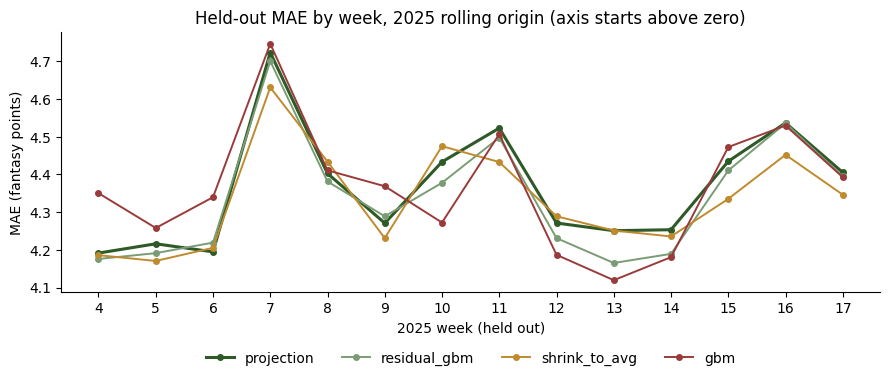

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
colors = {'projection': '#2d5a27', 'residual_gbm': '#7a9c74', 'shrink_to_avg': '#c08a2e', 'gbm': '#9a3b3b'}
for k in NAMES:
    ax.plot(per_week.index, per_week[k], marker='o', ms=4, lw=2.2 if k == 'projection' else 1.4, color=colors[k], label=k)
ax.set_xticks(test_weeks); ax.set_xlabel('2025 week (held out)'); ax.set_ylabel('MAE (fantasy points)')
ax.set_title('Held-out MAE by week, 2025 rolling origin (axis starts above zero)')
ax.legend(frameon=False, ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.18))
for s in ('top', 'right'): ax.spines[s].set_visible(False)
plt.tight_layout(); fig.savefig(OUT / 'projection_bakeoff_2025_by_week.png', dpi=130, bbox_inches='tight'); plt.show()

## Are the differences real?

Two paired bootstraps of each candidate's absolute error minus the projection's (positive = candidate worse):

* **rows**: resample player-weeks, as in the original notebook;
* **weeks**: resample whole weeks. Players in the same week share news, weather and game scripts, so their errors are not independent; this
  interval is the more honest one.

In [9]:
rng = np.random.default_rng(0)
n = len(preds); idx = rng.integers(0, n, size=(2000, n))
wk = preds.week.values; W = np.array(test_weeks)
wsum = {k: preds.groupby('week')['ae_' + k].sum().reindex(W).values for k in NAMES}
wn = preds.groupby('week').size().reindex(W).values
widx = rng.integers(0, len(W), size=(4000, len(W)))
rows = []
for k in NAMES[1:]:
    d = (preds['ae_' + k] - preds['ae_projection']).values
    boots = d[idx].mean(1)
    dw = wsum[k] - wsum['projection']
    wboots = dw[widx].sum(1) / wn[widx].sum(1)
    rows.append(dict(candidate=k, mean_diff_vs_projection=d.mean(),
                     ci_rows=f'{np.quantile(boots, 0.025):+.3f} to {np.quantile(boots, 0.975):+.3f}',
                     ci_weeks=f'{np.quantile(wboots, 0.025):+.3f} to {np.quantile(wboots, 0.975):+.3f}',
                     share_of_rows_better=(d < 0).mean(), weeks_better=int((dw < 0).sum())))
boot = pd.DataFrame(rows).set_index('candidate')
boot.round(3)

,mean_diff_vs_projection,ci_rows,ci_weeks,share_of_rows_better,weeks_better
candidate,,,,,
residual_gbm,-0.025,-0.036 to -0.014,-0.040 to -0.010,0.520,12
shrink_to_avg,-0.033,-0.068 to +0.003,-0.056 to -0.008,0.531,9
gbm,0.003,-0.033 to +0.038,-0.044 to +0.050,0.490,7


## By position

Pooled MAE over all held-out player-weeks, with the number of rows.

In [10]:
bypos = preds.groupby('posname')[['ae_' + k for k in NAMES]].mean().rename(columns=lambda c: c[3:])
bypos['n'] = preds.groupby('posname').size()
bypos = bypos.reindex([p for p in POS if p in bypos.index])
bypos['best'] = bypos[NAMES].idxmin(axis=1)
bypos.round(3)

,projection,residual_gbm,shrink_to_avg,gbm,n,best
posname,,,,,,
QB,6.578,6.393,6.429,6.312,416,gbm
RB,4.523,4.507,4.491,4.549,1088,shrink_to_avg
WR,4.333,4.325,4.327,4.383,1795,residual_gbm
TE,3.575,3.567,3.528,3.577,998,shrink_to_avg
K,3.781,3.778,3.784,3.791,409,residual_gbm


## Floor / ceiling coverage

Floors and ceilings are the 20th and 80th percentile of actual ÷ projected points per position (players projected above 3), and the target
is that 60% of actuals land inside `[projection × q20, projection × q80]`. Checked out of sample two ways:

* **all earlier weeks**: the quantiles are fitted on every week before the test week, as in `projection_bakeoff.ipynb`;
* **app window**: fitted on the last ≤ 4 completed weeks before the test week, which is what `src/engine/model.ts` actually does.

A position needs at least 25 training samples to be fitted, as in the app; thinner positions are skipped rather than given fallback
constants.

In [11]:
def ratio_q(d):
    d = d[d.proj > 3]
    return {p: (float(np.quantile(g.y / g.proj, 0.2)), float(np.quantile(g.y / g.proj, 0.8))) for p, g in d.groupby('posname') if len(g) >= 25}

def coverage(window):
    out, per_row = [], []
    for tw in test_weeks:
        trw = base[(base.week < tw) & (base.week >= (tw - window if window else 0))]
        q = ratio_q(trw); te = base[(base.week == tw) & (base.proj > 3) & base.posname.isin(q)]
        lo = te.proj * te.posname.map(lambda p: q[p][0]); hi = te.proj * te.posname.map(lambda p: q[p][1])
        inside = (te.y >= lo) & (te.y <= hi)
        out.append(dict(week=tw, n=len(te), coverage=inside.mean(), below_floor=(te.y < lo).mean(), above_ceiling=(te.y > hi).mean()))
        per_row.append(pd.DataFrame(dict(posname=te.posname, inside=inside)))
    return pd.DataFrame(out).set_index('week'), pd.concat(per_row)

cov_all, rows_all = coverage(None)
cov_app, rows_app = coverage(4)
pooled = lambda c: (c.coverage * c.n).sum() / c.n.sum()
cov_tbl = pd.DataFrame({'all earlier weeks': cov_all.coverage, 'app window (last 4)': cov_app.coverage, 'n': cov_all.n})
display(cov_tbl.T.round(3))
pos_tbl = pd.DataFrame({'all earlier weeks': rows_all.groupby('posname').inside.mean(), 'app window (last 4)': rows_app.groupby('posname').inside.mean(),
                        'n': rows_all.groupby('posname').size()}).reindex([p for p in POS if p in set(rows_all.posname)])
display(pos_tbl.T.round(3))
print(f'pooled coverage, all earlier weeks: {pooled(cov_all):.3f} | app window: {pooled(cov_app):.3f} | target 0.60')
print(f'below floor / above ceiling (all earlier weeks): {(cov_all.below_floor * cov_all.n).sum() / cov_all.n.sum():.3f} / '
      f'{(cov_all.above_ceiling * cov_all.n).sum() / cov_all.n.sum():.3f}  (target 0.20 / 0.20)')
print('ratio quantiles fitted on the whole season:', {p: tuple(round(v, 2) for v in qq) for p, qq in ratio_q(base).items()})

week,4,5,6,7,8,9,10,11,12,13,14,15,16,17
all earlier weeks,0.586,0.55,0.585,0.535,0.559,0.603,0.568,0.621,0.585,0.599,0.628,0.565,0.592,0.598
app window (last 4),0.586,0.55,0.566,0.550,0.572,0.632,0.598,0.632,0.606,0.588,0.632,0.543,0.574,0.620
n,268.000,242.00,265.000,258.000,222.000,247.000,241.000,253.000,246.000,274.000,247.000,278.000,282.000,276.000


posname,QB,RB,WR,TE,K
all earlier weeks,0.579,0.571,0.589,0.574,0.611
app window (last 4),0.572,0.578,0.598,0.579,0.611
n,416.000,842.000,1347.000,585.000,409.000


pooled coverage, all earlier weeks: 0.584 | app window: 0.589 | target 0.60
below floor / above ceiling (all earlier weeks): 0.213 / 0.203  (target 0.20 / 0.20)
ratio quantiles fitted on the whole season: {'K': (0.47, 1.46), 'QB': (0.52, 1.18), 'RB': (0.38, 1.45), 'TE': (0.31, 1.57), 'WR': (0.29, 1.49)}


## Does the plain projection still win?

Ranked by the mean across test weeks; printed from the numbers so the verdict cannot drift from the tables.

In [12]:
rank = summary['mean across test weeks'].sort_values()
winner = rank.index[0]
print('ranking (MAE):', {k: round(v, 3) for k, v in rank.items()})
print('winner:', winner)
print('plain projection wins' if winner == 'projection' else f'plain projection does NOT win: {winner} is lower by {rank["projection"] - rank[winner]:.3f} points')
print('weeks won:', summary['weeks won'].to_dict())

ranking (MAE): {'shrink_to_avg': 4.334, 'residual_gbm': 4.34, 'projection': 4.365, 'gbm': 4.367}
winner: shrink_to_avg
plain projection does NOT win: shrink_to_avg is lower by 0.031 points
weeks won: {'projection': 1, 'residual_gbm': 2, 'shrink_to_avg': 7, 'gbm': 4}


## Conclusion

**Over a full season the plain projection does not win, but nothing beats it by much.** Fourteen held-out weeks of 2025 (4,706
player-weeks), mean MAE across weeks:

| candidate | MAE | vs projection (95% CI, week bootstrap) | weeks won |
|---|---|---|---|
| shrink_to_avg | **4.334** | −0.033 (−0.056 to −0.008) | 7 |
| residual_gbm | 4.340 | −0.025 (−0.040 to −0.010) | 2 |
| projection | 4.365 | – | 1 |
| gbm | 4.367 | +0.003 (−0.044 to +0.050) | 4 |

* The two light corrections are better, and the week-level intervals exclude zero, but the gain is **0.03 points per player-week (0.7%)**.
  For a 9-starter lineup that is about 0.3 points a week, far inside the ~19-point team SD. Users would not notice it.
* About 40% of shrink-to-average's gain comes from quarterbacks (MAE 6.58 → 6.43), the position where Sleeper's 2025 projections were
  weakest; at RB, WR, TE and K all four candidates are within 0.05 points.
* The full GBM gets better as its training set grows: worst in weeks 4-9, best of all in weeks 10, 12, 13 and 14. On the season it ties
  the projection. The 2026 run, trained on only two weeks, saw it at its worst.
* So the 2026 weeks 4-5 result ("projection wins") is the early-season picture; it does not hold for a whole season.

**Recommendation: keep the plain projection as the player mean.** The best alternative buys 0.7% and needs each player's season
history in the engine. If the app ever wants it, `shrink_to_avg` (one line, no model) is the one to add, since it beat the projection
in 9 of 14 weeks; it should be re-tested on real-time projections first (below).

**Floors and ceilings: fine.** Pooled coverage 58.4% fitting on all earlier weeks, **58.9%** with the app's own last-4-weeks window,
against a 60% target; 21.3% of actuals fall below the floor and 20.3% above the ceiling (target 20 / 20). Every position is between
57% and 61%. The bands are very slightly narrow, consistent with the 58.6% of the 2026 run.

**Caveat: all of this is measured on rewritten projections.** For a finished week Sleeper returns a projection updated after the games:
every 2025 row projected above 0.5 points carries a `last_modified` after the week's last kickoff, and only 5 of 6,174 such players
did not play (in real time, late scratches are far more common). So these MAEs are lower than the error of the projection the app
actually showed before kickoff, and the coverage is a little higher. The candidates are compared on the same rewritten projection,
so the ranking is fair, but whether `shrink_to_avg` still helps when the projection does not know who sits needs pre-kickoff
snapshots. `projection_bakeoff_refresh.ipynb` measures the size of the flattery on 2026 week 6, where the saved fixture holds the
real pre-kickoff projection.
